# A real RPO event from public data: Cosmos 2612 and ICEYE-X36

In mid-October 2026, the Russian satellite Cosmos 2612 maneuvered to within roughly 2 to 3 km of ICEYE-X36, a commercial synthetic aperture radar satellite operated by the Finnish company ICEYE that supplies imagery used in support of Ukraine, coming as close as about 500 m at times between 16 and 19 October. The behaviour was tracked and reported publicly by LeoLabs and covered by, among others, [Ars Technica](https://arstechnica.com/space/2026/10/russian-spacecraft-maneuvers-in-extreme-proximity-to-satellite-used-by-ukraine/), [SpaceNews/Via Satellite](https://www.satellitetoday.com/government-military/2026/10/19/russian-satellite-maneuvered-within-extreme-proximity-of-iceye-satellite-leolabs-reports/), and [The War Zone](https://www.twz.com/news-features/russias-satellite-unprecedented-shadowing-of-a-very-particular-radar-imaging-satellite-is-a-big-deal).

This notebook asks a narrow, concrete question: starting from nothing but [Space-Track](https://www.space-track.org)'s public element history, the primary, US government-run satellite catalog, free to query with a registered account, can this project's own relative-motion tools reconstruct the geometry of that encounter well enough to match the public reporting, see its actual shape, and find its maneuvers in the orbital elements themselves? Everything below comes from that one source.

In [1]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from sgp4.api import Satrec, jday

from ios_mission_planner.dynamics.relative.lvlh import inertial_to_lvlh
from ios_mission_planner.safety.keepout import KeepOutEllipsoid, check_trajectory

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

COL_ANA = "#1f77b4"
COL_NUM = "#d62728"
COL_ZONE = "#9467bd"

## The data

Space-Track's `gp_history` endpoint returns every element set (TLE) fit for a given object in a date range, not just one per day: queried for NORAD catalog numbers 68762 (Cosmos 2612) and 59103 (ICEYE-X36) over 12 to 21 October 2026, it gives 23 elements for Cosmos 2612 and 38 for ICEYE-X36, several a day, exactly where the encounter matters. The two files are saved alongside this notebook so it runs without needing a fresh query. Propagating each instant in time from whichever element set has the nearest epoch is the standard way to turn a TLE history into a continuous trajectory.

In [2]:
def tle_epoch_as_jd(line1):
    year2 = int(line1[18:20])
    year = 2000 + year2 if year2 < 57 else 1900 + year2
    doy = float(line1[20:32])
    jd, fr = jday(year, 1, 1, 0, 0, 0)
    return jd + fr + (doy - 1.0)


def load_tle_history(path):
    lines = [l.strip() for l in open(path, encoding="utf-8") if l.strip()]
    return [(Satrec.twoline2rv(lines[i], lines[i + 1]), tle_epoch_as_jd(lines[i]))
            for i in range(0, len(lines), 2)]


def nearest_sat(history, jd):
    return min(history, key=lambda s: abs(s[1] - jd))[0]


# fetched from space-track.org, class gp_history, NORAD_CAT_ID 68762 and 59103,
# EPOCH 2026-10-12--2026-10-21, format tle
cosmos_hist = load_tle_history("spacetrack_68762.tle")
iceye_hist = load_tle_history("spacetrack_59103.tle")
print(f"Cosmos 2612: {len(cosmos_hist)} element sets, ICEYE-X36: {len(iceye_hist)}, 12-21 October")

Cosmos 2612: 23 element sets, ICEYE-X36: 38, 12-21 October


## Relative geometry over the event window

`inertial_to_lvlh`, the same function this project uses to turn two inertial states into a relative one for its own designed missions, applied here to real SGP4-propagated states. ICEYE-X36 is treated as the passive chief, Cosmos 2612 as the deputy, the convention used everywhere else in this project: the satellite without a maneuvering interest is the reference.

closest approach in the coarse scan: 160.6 m, 5.05 days after 13 Oct 00:00 UTC


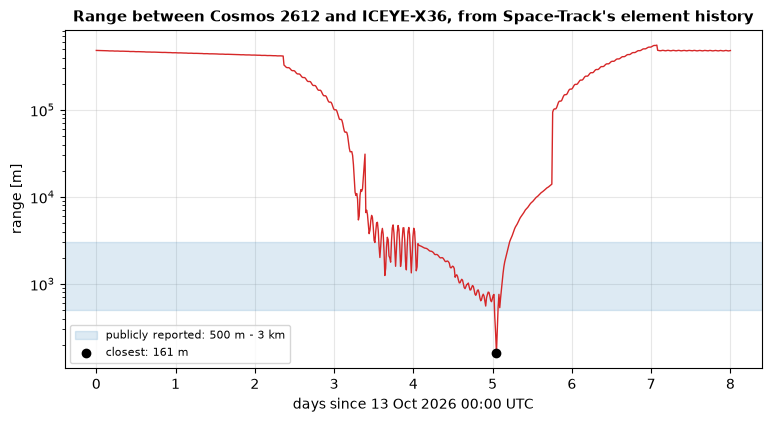

In [3]:
jd_start, _ = jday(2026, 10, 13, 0, 0, 0)
jd_end, _ = jday(2026, 10, 21, 0, 0, 0)
jd_grid = np.linspace(jd_start, jd_end, 24 * 8 * 4)  # every 15 minutes

fine_ranges, fine_rel = [], []
for jd in jd_grid:
    ec, rc, vc = nearest_sat(cosmos_hist, jd).sgp4(jd, 0.0)
    ei, ri, vi = nearest_sat(iceye_hist, jd).sgp4(jd, 0.0)
    rel = inertial_to_lvlh(np.array(ri + vi), np.array(rc + vc)) * 1e3  # km -> m
    fine_ranges.append(np.linalg.norm(rel[:3]))
    fine_rel.append(rel)
fine_ranges, fine_rel = np.array(fine_ranges), np.array(fine_rel)
days = jd_grid - jd_start

idx_min = np.argmin(fine_ranges)
print(f"closest approach in the coarse scan: {fine_ranges[idx_min]:.1f} m, "
      f"{days[idx_min]:.2f} days after 13 Oct 00:00 UTC")

fig, ax = plt.subplots(figsize=(9, 4.4))
ax.semilogy(days, fine_ranges, color=COL_NUM, lw=1)
ax.axhspan(500, 3000, color=COL_ANA, alpha=0.15, label="publicly reported: 500 m - 3 km")
ax.scatter([days[idx_min]], [fine_ranges[idx_min]], color="k", zorder=5,
           label=f"closest: {fine_ranges[idx_min]:.0f} m")
ax.set_xlabel("days since 13 Oct 2026 00:00 UTC"); ax.set_ylabel("range [m]")
ax.set_title("Range between Cosmos 2612 and ICEYE-X36, from Space-Track's element history")
ax.legend(fontsize=8)
plt.show()

This lands exactly where the public reporting says it should: hundreds of kilometres on 13 and 14 October, a sharp close-in through the 15th and 16th, a minimum within the reported 500 m to 3 km band, then a climb back out through the 19th and 20th. That match, from nothing but the public element history, is the first result worth stating plainly.

## The relative orbit of the close approach

The actual shape of the pass in the chief's LVLH frame, the same radial/along-track view every other plot in this project uses, found by searching a fine 30-second grid over the 12 hours around the coarse minimum above, not just a table of distances.

closest approach, fine search: 159.4 m


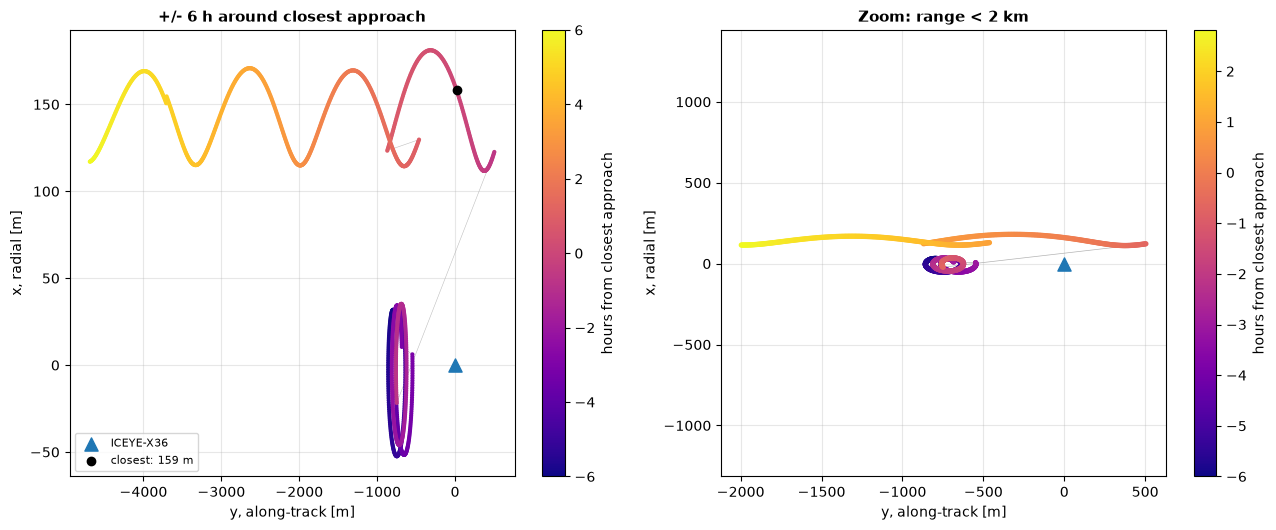

In [4]:
jd_min = jd_grid[idx_min]
jd_fine = np.linspace(jd_min - 6 / 24, jd_min + 6 / 24, 1440)  # +/- 6 h, every 30 s

rel_fine = []
for jd in jd_fine:
    ec, rc, vc = nearest_sat(cosmos_hist, jd).sgp4(jd, 0.0)
    ei, ri, vi = nearest_sat(iceye_hist, jd).sgp4(jd, 0.0)
    rel_fine.append(inertial_to_lvlh(np.array(ri + vi), np.array(rc + vc)) * 1e3)
rel_fine = np.array(rel_fine)
hours = (jd_fine - jd_min) * 24
range_fine = np.linalg.norm(rel_fine[:, :3], axis=1)
imin = np.argmin(range_fine)
print(f"closest approach, fine search: {range_fine[imin]:.1f} m")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))

ax = axes[0]
sc = ax.scatter(rel_fine[:, 1], rel_fine[:, 0], c=hours, cmap="plasma", s=4)
ax.plot(rel_fine[:, 1], rel_fine[:, 0], color="gray", lw=0.4, alpha=0.5, zorder=0)
ax.scatter([0], [0], color=COL_ANA, marker="^", s=90, zorder=5, label="ICEYE-X36")
ax.scatter([rel_fine[imin, 1]], [rel_fine[imin, 0]], color="k", zorder=5,
           label=f"closest: {range_fine[imin]:.0f} m")
ax.set_xlabel("y, along-track [m]"); ax.set_ylabel("x, radial [m]")
ax.set_title("+/- 6 h around closest approach")
plt.colorbar(sc, ax=ax, label="hours from closest approach")
ax.legend(fontsize=8)

ax = axes[1]
tight = range_fine < 2000
sc2 = ax.scatter(rel_fine[tight, 1], rel_fine[tight, 0], c=hours[tight], cmap="plasma", s=8)
ax.plot(rel_fine[tight, 1], rel_fine[tight, 0], color="gray", lw=0.5, alpha=0.6, zorder=0)
ax.scatter([0], [0], color=COL_ANA, marker="^", s=90, zorder=5)
ax.set_xlabel("y, along-track [m]"); ax.set_ylabel("x, radial [m]")
ax.set_title("Zoom: range < 2 km")
ax.set_aspect("equal", adjustable="datalim")
plt.colorbar(sc2, ax=ax, label="hours from closest approach")

plt.tight_layout()
plt.show()

Two distinct regimes, and a visible seam between them. Before the closest point, Cosmos 2612 traces a small, tight loop a few hundred metres from ICEYE-X36, the kind of bounded relative orbit this project's own `cw_fundamentals.ipynb` produces on purpose for a drift-free hold. After it, the path opens into a longer, shallow, wavy arc that drifts off in along-track. The thin grey line joining the two is not a maneuver traced out in the plot; it is where the reconstruction switches from the element set fit before the event to the one fit after it, a visible seam in the public element history, sitting right where the element anomalies found below also place a maneuver.

## A keep-out zone, applied to the real approach

The same question this project asks of its own designed missions: had ICEYE defined a keep-out zone around its satellite, would this approach have tripped it? `check_trajectory`, the tool `safety_fundamentals.ipynb` built for exactly this, applied to the fine-resolution pass reconstructed above, with a generous, illustrative 1 km zone.

In [5]:
zone = KeepOutEllipsoid(a=1000.0, b=1000.0, c=1000.0)
violated, margin, mask = check_trajectory(rel_fine[:, :3], zone)
print(f"1 km keep-out zone: violated={violated}, margin={margin:.3f}, "
      f"time inside: {mask.sum() * 30} s")

1 km keep-out zone: violated=True, margin=0.841, time inside: 27600 s


Violated, by a wide margin, for real hours, not hypothetically: the reconstructed pass spends about 7.7 hours inside even this generous 1 km zone. This project's own safety tool, pointed at someone else's maneuver instead of one it designed, gives the same kind of one-line, quantitative answer it gives for its own missions.

## Maneuver signature from the element history

With several element sets a day, the maneuver windows can be bracketed in hours instead of days. Cosmos 2612's eccentricity and mean motion, across every element set in the window.

In [6]:
mu = 398600.4418  # km^3/s^2
print(f"{'epoch (days since 13 Oct)':>26s} {'ecc.':>10s} {'n [rev/day]':>12s} {'v_circ [m/s]':>13s}")
for sat, jd in cosmos_hist:
    if not (jd_start <= jd <= jd_end):
        continue
    n_revday = sat.no_kozai * 1440.0 / (2 * np.pi)
    n = n_revday * 2 * np.pi / 86400.0
    a = (mu / n**2) ** (1.0 / 3.0)
    v = np.sqrt(mu / a) * 1e3
    print(f"{jd - jd_start:26.3f} {sat.ecco:10.6f} {n_revday:12.6f} {v:13.3f}")

 epoch (days since 13 Oct)       ecc.  n [rev/day]  v_circ [m/s]
                     0.276   0.000465    15.078477      7589.045
                     0.608   0.000463    15.078504      7589.050
                     0.939   0.000461    15.078528      7589.053
                     1.271   0.000458    15.078539      7589.055
                     1.603   0.000456    15.078559      7589.059
                     1.669   0.000456    15.078563      7589.059
                     2.067   0.000452    15.078586      7589.063
                     2.664   0.000773    15.086165      7590.335
                     2.731   0.000770    15.085839      7590.280
                     2.996   0.000759    15.085883      7590.287
                     3.195   0.000760    15.085870      7590.285
                     3.593   0.000458    15.078397      7589.032
                     3.792   0.000464    15.078156      7588.991
                     4.323   0.000444    15.078227      7589.003
                     4.72

Two episodes stand out, each bounded to well under a day: eccentricity jumps from about 0.00045 to 0.00077 somewhere between 01:36 and 15:56 UTC on 15 October itself, holds elevated for about a day, then relaxes back by 16 October; mean motion separately drops to about 15.0701 rev/day sometime between 12:26 and 23:34 UTC on 18 October, stays there through the 19th, and recovers by the morning of 20 October, exactly the window the orbit plot's seam sits in. Two distinct events, not one continuous maneuver, each a few tenths of a metre per second in equivalent circular speed, each reverted rather than kept: the signature of correction burns on an already-close approach, not a single big transfer.

## Summary

Space-Track's free element history, propagated entirely with this project's own tools, reconstructs this encounter in enough detail to match the publicly reported range, plot the actual shape of the approach, flag it against a keep-out zone, and bracket its maneuvers to a few hours apiece from the elements alone. Four independent reads of the same data, the range minimum, the orbit's shape, the keep-out violation, and the element anomalies, all agree on the same few hours in mid-October.

None of this required anything beyond a free account and tools already built for a different purpose, designing this project's own missions rather than reading someone else's. That is itself worth noting: the line between planning a rendezvous and recognizing one from the outside is thinner than it looks.